# Сборка двумерного кластера из N частиц и коррелятор плотности

Продолжение исходного `gas.ipynb`: сохраняем обозначения `Uij`, `force`, `forceIJ`, `atoms`, `gas`, `y0`, `RV` и исходный парный потенциал.

**Что запускать:** выберите Python-ядро и нажмите **Run All / Выполнить всё**. Ниже появятся начальное и конечное состояния, анимация с кнопкой ▶, плотность и коррелятор. Основные настройки собраны в одной ячейке: `N = 16` можно заменить на 10 или 20.

Это учебная **двумерная модель** частиц одинаковой массы m = 1 в условных единицах. Упорядоченный конечный кластер служит моделью нанокристалла; размер в нанометрах и свойства конкретного вещества здесь не задаются. Наличие идеального кристалла не предполагается заранее: возможны дефекты и метастабильные состояния.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as si
from scipy.special import i0e
from matplotlib.animation import FuncAnimation
from matplotlib.collections import LineCollection
from IPython.display import HTML, display

# Если пакетов нет, один раз выполните в отдельной ячейке:
# %pip install numpy scipy matplotlib ipython


## 1. Взаимодействие и охлаждение

Потенциал и сила **не изменены** относительно исходника:
$$U_{ij}(r)=\frac{1}{r^2}-\frac{e^{-r/10}}{r},\qquad
F(r)=-U'_{ij}(r)=\frac{2}{r^3}-e^{-r/10}\left(\frac{0.1}{r}+\frac{1}{r^2}\right).$$

Уравнение движения:
$$\dot{\mathbf R}_i=\mathbf V_i,\qquad
\dot{\mathbf V}_i=\sum_{j\ne i}\mathbf F_{ij}-k\mathbf R_i-\alpha\mathbf V_i.$$

`k` — сила внешней гармонической ловушки, которая удерживает частицы рядом. `alpha` — трение: энергия уходит из системы, и частицы могут осесть в упорядоченную структуру. Это диссипативная сборка, а не газ в тепловом равновесии: случайного теплового шума в модели нет.

В исходном запуске были `k=0.009`, `alpha=0.01`. Здесь **k сохранено, alpha = 0.10** для более быстрого охлаждения. Начальные положения теперь случайные и разнесённые; частицы не расставляются в готовую решётку. Все изменения параметров видны в следующей ячейке.


In [2]:
N = 16                 # число частиц: попробуйте 10, 16, 20
tmax = 300.0            # длительность моделирования
k = 0.009              # исходная удерживающая ловушка; 0 — без ловушки
alpha = 0.10           # трение / скорость охлаждения
seed = 42              # фиксированное случайное начальное состояние
initial_radius = 8.0   # радиус начального облака
min_distance = 1.5     # исключаем сильное начальное перекрытие
initial_speed = 0.15   # масштаб начальных скоростей
max_step = 0.10        # максимальный внутренний шаг интегрирования
num_times = 1501       # равномерные моменты сохранения результата
sigma = 0.25           # ширина гауссовой плотности частицы
late_fraction = 0.20   # усреднение коррелятора по последним 20% времени
num_corr_frames = 20   # число равномерно взятых поздних кадров
max_animation_frames = 240

assert isinstance(N, (int, np.integer)) and N >= 2
assert tmax > 0 and max_step > 0 and num_times >= 2
assert k >= 0 and alpha >= 0 and sigma > 0
assert 0 < late_fraction <= 1 and num_corr_frames >= 1


In [3]:
def Uij(dR):
    return 1 / dR**2 - np.exp(-dR / 10) / dR


def force(dR):  # -dU/dR
    return 2 / dR**3 - np.exp(-dR / 10) * (0.1 / dR + 1 / dR**2)


def forceIJ(Ri, Rj):
    dRij = np.asarray(Ri) - np.asarray(Rj)
    modR = np.linalg.norm(dRij)
    if modR == 0:
        raise ValueError("Совпали координаты двух частиц.")
    return force(modR) * dRij / modR


def atoms(t, y, k, alpha):
    N = len(y) // 4
    RV = y.reshape(2, 2, N)
    R, V = RV[0], RV[1]
    # dRij[:, i, j] = Ri - Rj; считаем сразу все пары через NumPy.
    dRij = R[:, :, None] - R[:, None, :]
    modR = np.linalg.norm(dRij, axis=0)
    mask = ~np.eye(N, dtype=bool)
    if np.any(modR[mask] == 0):
        raise ValueError("Совпали координаты двух частиц.")
    np.fill_diagonal(modR, 1.0)  # только для безопасного деления на диагонали
    coefficients = force(modR) / modR
    np.fill_diagonal(coefficients, 0.0)  # силы на себя нет
    Fi = np.sum(dRij * coefficients[None, :, :], axis=2)
    Fi -= k * R + alpha * V
    return np.stack((V, Fi)).reshape(4 * N)


def initial_conditions(N, seed, radius, min_distance, speed):
    if N < 2 or radius <= 0 or min_distance <= 0 or speed < 0:
        raise ValueError("Проверьте параметры начального облака.")
    rng = np.random.default_rng(seed)
    R = []
    for attempt in range(100000):
        r = radius * np.sqrt(rng.random())
        phi = rng.uniform(0, 2 * np.pi)
        candidate = r * np.array([np.cos(phi), np.sin(phi)])
        if not R or np.all(np.linalg.norm(np.array(R) - candidate, axis=1) >= min_distance):
            R.append(candidate)
        if len(R) == N:
            break
    if len(R) != N:
        raise ValueError("Не удалось разместить N частиц: увеличьте initial_radius.")
    y0 = np.zeros((2, 2, N))
    y0[0] = np.array(R).T
    y0[0] -= y0[0].mean(axis=1, keepdims=True)
    y0[1] = rng.normal(0, speed, size=(2, N))
    y0[1] -= y0[1].mean(axis=1, keepdims=True)
    return y0


def gas(y0, tmax, k=0.009, alpha=0.10, num_times=1501,
        max_step=0.1, rtol=1e-7, atol=1e-9):
    y0 = np.asarray(y0, dtype=float)
    if y0.ndim != 3 or y0.shape[:2] != (2, 2) or y0.shape[2] < 2:
        raise ValueError("Ожидается y0.shape = (2, 2, N), N >= 2.")
    if not np.all(np.isfinite(y0)) or tmax <= 0 or k < 0 or alpha < 0:
        raise ValueError("Проверьте начальные условия, tmax, k и alpha.")
    N = y0.shape[2]
    print(f"Расчёт N={N}, tmax={tmax}, k={k}, alpha={alpha}...", flush=True)
    sol = si.solve_ivp(
        fun=atoms, y0=y0.reshape(4 * N), t_span=(0, tmax),
        args=(k, alpha), t_eval=np.linspace(0, tmax, num_times),
        max_step=max_step, rtol=rtol, atol=atol,
    )
    if not sol.success:
        raise RuntimeError(sol.message)
    RV = sol.y.reshape(2, 2, N, len(sol.t))
    print(f"Готово: {len(sol.t)} кадров, вызовов правой части: {sol.nfev}.")
    return sol.t, RV


In [4]:
y0 = initial_conditions(N, seed, initial_radius, min_distance, initial_speed)
t, RV = gas(y0, tmax, k, alpha, num_times, max_step)
print("RV.shape =", RV.shape)
# RV[0, 0, i, :] — x_i(t); RV[0, 1, i, :] — y_i(t)
# RV[1, 0, i, :] — vx_i(t); RV[1, 1, i, :] — vy_i(t)


Расчёт N=16, tmax=300.0, k=0.009, alpha=0.1...
Готово: 1501 кадров, вызовов правой части: 19664.
RV.shape = (2, 2, 16, 1501)


## 2. Начало, траектории, конечный кластер и охлаждение

Тонкие линии в конечном состоянии соединяют близких соседей. Порог связи равен 1.35 медианного расстояния до ближайшего соседа **в конечном состоянии**: это только способ отображения, он не влияет на силы.

Для проверки охлаждения считаем
$$E=\frac12\sum_i |\mathbf V_i|^2+\sum_{i<j}U_{ij}(r_{ij})+\frac{k}{2}\sum_i|\mathbf R_i|^2,$$
причём $dE/dt=-\alpha\sum_i|\mathbf V_i|^2\leq0$. Потенциальная энергия пары учитывается один раз. При конечной точности решателя возможны малые численные отклонения.


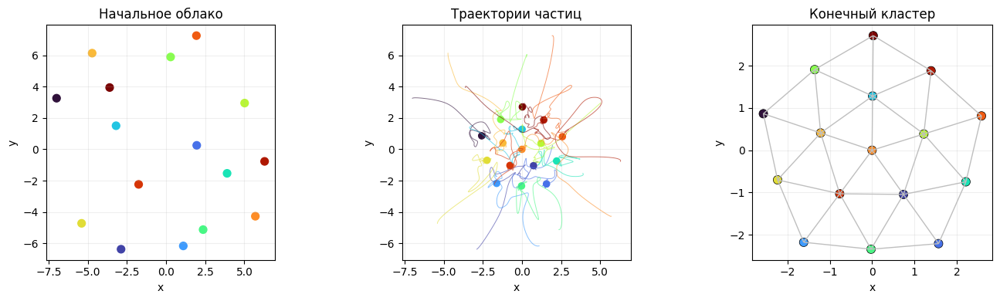

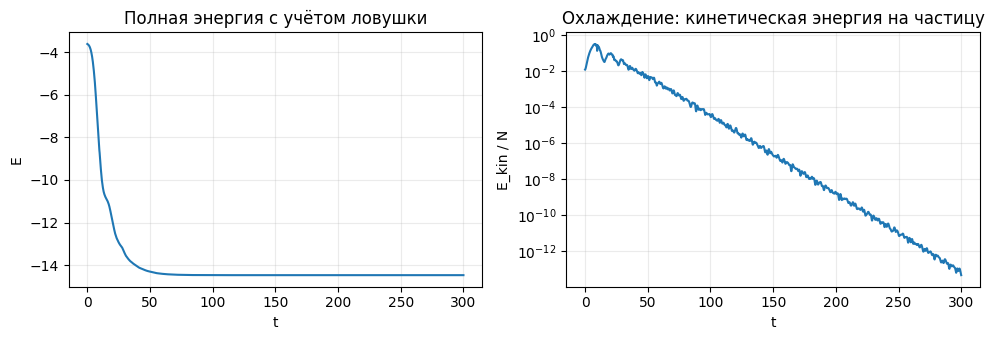

Медианное расстояние до ближайшего соседа: 1.4276
Конечная кинетическая энергия на частицу: 4.850e-14
Максимальное приращение полной энергии между кадрами: -2.132e-14
Изменение полной энергии за окно коррелятора: -9.410e-10


In [5]:
def energies(RV, k):
    R, V = RV[0], RV[1]
    N = R.shape[1]
    kinetic = 0.5 * np.sum(V**2, axis=(0, 1))
    potential = 0.5 * k * np.sum(R**2, axis=(0, 1))
    for i in range(N):
        for j in range(i + 1, N):
            potential += Uij(np.linalg.norm(R[:, i] - R[:, j], axis=0))
    return kinetic, potential, kinetic + potential


def neighbor_segments(R, cutoff):
    # R.shape = (2, N); возвращаем отрезки между близкими соседями.
    d = np.linalg.norm(R[:, :, None] - R[:, None, :], axis=0)
    i, j = np.where(np.triu((d > 0) & (d < cutoff), k=1))
    return np.stack((R[:, i].T, R[:, j].T), axis=1)


Rfinal = RV[0, :, :, -1]
distances = np.linalg.norm(Rfinal[:, :, None] - Rfinal[:, None, :], axis=0)
np.fill_diagonal(distances, np.inf)
nearest_distance = np.median(distances.min(axis=1))
bond_cutoff = 1.35 * nearest_distance
kinetic, potential, total = energies(RV, k)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = plt.cm.turbo(np.linspace(0, 1, N))
axes[0].scatter(*RV[0, :, :, 0], c=colors, s=50)
axes[0].set_title("Начальное облако")
for i in range(N):
    axes[1].plot(RV[0, 0, i], RV[0, 1, i], color=colors[i], lw=0.7, alpha=0.6)
axes[1].scatter(*Rfinal, c=colors, s=35)
axes[1].set_title("Траектории частиц")
axes[2].add_collection(LineCollection(neighbor_segments(Rfinal, bond_cutoff), colors='0.75', lw=1))
axes[2].scatter(*Rfinal, c=colors, s=65, edgecolors='black', linewidths=0.5)
axes[2].set_title("Конечный кластер")
for ax in axes:
    ax.set(xlabel='x', ylabel='y', aspect='equal')
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(t, total)
axes[0].set(xlabel='t', ylabel='E', title='Полная энергия с учётом ловушки')
axes[1].semilogy(t, np.maximum(kinetic / N, 1e-16))
axes[1].set(xlabel='t', ylabel='E_kin / N', title='Охлаждение: кинетическая энергия на частицу')
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
late_index = np.searchsorted(t, (1 - late_fraction) * t[-1])
print(f"Медианное расстояние до ближайшего соседа: {nearest_distance:.4f}")
print(f"Конечная кинетическая энергия на частицу: {kinetic[-1] / N:.3e}")
print(f"Максимальное приращение полной энергии между кадрами: {np.diff(total).max():.3e}")
print(f"Изменение полной энергии за окно коррелятора: {total[-1] - total[late_index]:.3e}")


## 3. Анимация сборки

Нажмите ▶ под картинкой. Время модельное, скорость воспроизведения задаётся `interval` и не является физической единицей. Цвет частицы сохраняется. Связи показываются по тому же порогу, что и выше.

Если анимация не отображается в VS Code, откройте ноутбук через Jupyter Notebook/Lab; для локального доверенного файла может потребоваться включить доверие к ноутбуку. Обычные графики доступны независимо от анимации.


In [6]:
def animate_gas(t, RV, bond_cutoff, max_frames=240):
    frames = np.unique(np.linspace(0, len(t) - 1, min(max_frames, len(t))).astype(int))
    R = RV[0]
    extent = np.max(np.abs(R)) + 1.0
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.set(xlim=(-extent, extent), ylim=(-extent, extent),
           xlabel='x', ylabel='y', aspect='equal')
    ax.grid(alpha=0.2)
    particles = ax.scatter(*R[:, :, 0], c=colors, s=65, edgecolors='black', linewidths=0.4)
    bonds = LineCollection([], colors='0.75', linewidths=1, zorder=0)
    ax.add_collection(bonds)
    title = ax.set_title('')

    def update(frame):
        current = R[:, :, frame]
        particles.set_offsets(current.T)
        bonds.set_segments(neighbor_segments(current, bond_cutoff))
        title.set_text(f'N = {R.shape[1]}   t = {t[frame]:.1f} / {t[-1]:.1f}')
        return particles, bonds, title

    animation = FuncAnimation(fig, update, frames=frames, interval=50, blit=False)
    html = animation.to_jshtml(default_mode='once')
    plt.close(fig)
    return animation, html

plt.rcParams['animation.embed_limit'] = 50  # МБ; число кадров ограничено выше
animation, animation_html = animate_gas(t, RV, bond_cutoff, max_animation_frames)
display(HTML(animation_html))


<Animation: press Play>

## 4. Плотность и точное определение коррелятора

Заменяем дельта-функции нормированными двумерными гауссианами:
$$\rho(\mathbf r,t)=\sum_{i=1}^N\frac{1}{2\pi\sigma^2}
\exp\left[-\frac{|\mathbf r-\mathbf R_i(t)|^2}{2\sigma^2}\right],
\qquad \int\rho\,d^2r=N.$$

Определяем пространственное и временное среднее для конечного изолированного кластера:
$$K(\Delta\mathbf r)=\frac{1}{A}\left\langle\int_{\mathbb R^2}
\rho(\mathbf r,t)\rho(\mathbf r+\Delta\mathbf r,t)\,d^2r\right\rangle_t.$$
`A` — **фиксированная** площадь квадрата, охватывающего всю траекторию с запасом 4σ. Она задаёт нормировку, не является стенкой или периодической ячейкой. Интеграл по пространству берётся аналитически по всей плоскости, поэтому нет обрезания гауссов и искусственного склеивания противоположных границ.

Произведение двух гауссиан можно проинтегрировать точно:
$$K(\Delta\mathbf r)=\frac{1}{4\pi\sigma^2 A}
\left\langle\sum_{i,j}\exp\left[-\frac{|\Delta\mathbf r-(\mathbf R_j-\mathbf R_i)|^2}{4\sigma^2}\right]\right\rangle_t.$$

Для графика по одному расстоянию усредняем также по направлению сдвига:
$$K(s)=\frac{1}{2\pi}\int_0^{2\pi} K(s\cos\varphi,s\sin\varphi)\,d\varphi,\quad s=|\Delta\mathbf r|.$$
В коде это вычисляется аналитически через функцию Бесселя I₀. Не нужно подставлять один вектор сдвига вдоль оси x вместо углового среднего.

**Самокорреляция:** члены i = j дают известный центральный пик
$$K_{\rm self}(s)=\frac{N}{4\pi\sigma^2 A}\exp[-s^2/(4\sigma^2)].$$
Полный K включает его. Для наблюдения расстояний между **разными** частицами отдельно показываем `K_pair` без i = j. Это не нормированная радиальная функция g(r): кластер конечный, плотность неоднородна, деления на площадь колец здесь не требуется.


In [7]:
def rho(R, X, Y, sigma):
    if sigma <= 0:
        raise ValueError("sigma должна быть положительной.")
    density = np.zeros_like(X, dtype=float)
    for i in range(R.shape[1]):
        density += np.exp(-((X - R[0, i])**2 + (Y - R[1, i])**2) / (2 * sigma**2))
    return density / (2 * np.pi * sigma**2)


def K_radial(R_frames, dr, sigma, A):
    """R_frames.shape = (2, N, число кадров). Возвращает K и K_pair."""
    if sigma <= 0 or A <= 0:
        raise ValueError("sigma и A должны быть положительными.")
    N = R_frames.shape[1]
    dr = np.asarray(dr, dtype=float)
    if np.any(dr < 0) or R_frames.shape[2] == 0:
        raise ValueError("Нужны неотрицательные сдвиги и хотя бы один кадр.")
    pair_mask = ~np.eye(N, dtype=bool)
    K_pair = np.zeros_like(dr)
    for frame in range(R_frames.shape[2]):
        R = R_frames[:, :, frame]
        d = np.linalg.norm(R[:, :, None] - R[:, None, :], axis=0)[pair_mask]
        z = dr[:, None] * d[None, :] / (2 * sigma**2)
        # i0e(z) = exp(-|z|)*I0(z): эта форма не переполняется.
        terms = np.exp(-(dr[:, None] - d[None, :])**2 / (4 * sigma**2)) * i0e(z)
        K_pair += terms.sum(axis=1)
    K_pair /= R_frames.shape[2] * 4 * np.pi * sigma**2 * A
    K_self = N / (4 * np.pi * sigma**2 * A) * np.exp(-dr**2 / (4 * sigma**2))
    return K_pair + K_self, K_pair


def K_map(R_frames, DX, DY, sigma, A):
    """Полный векторный коррелятор, включая самокорреляцию."""
    result = np.zeros_like(DX, dtype=float)
    for frame in range(R_frames.shape[2]):
        R = R_frames[:, :, frame]
        N = R.shape[1]
        for i in range(N):
            for j in range(N):
                d = R[:, j] - R[:, i]
                result += np.exp(-((DX - d[0])**2 + (DY - d[1])**2) / (4 * sigma**2))
    return result / (R_frames.shape[2] * 4 * np.pi * sigma**2 * A)


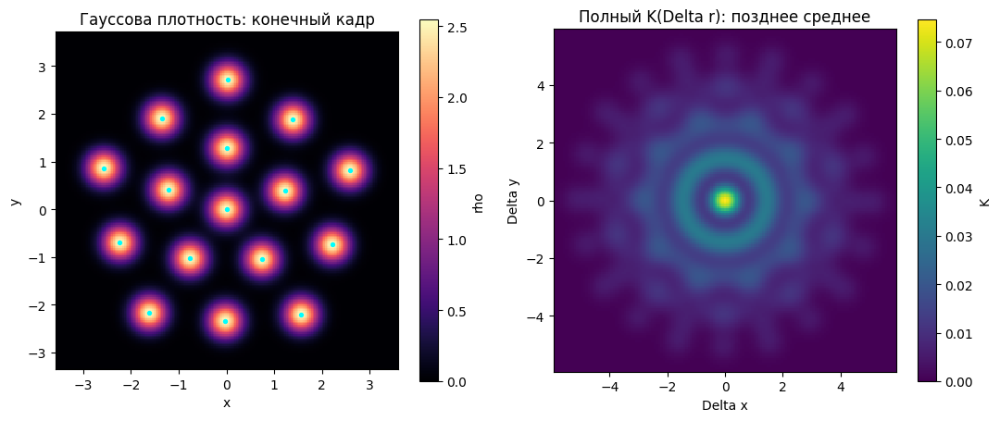

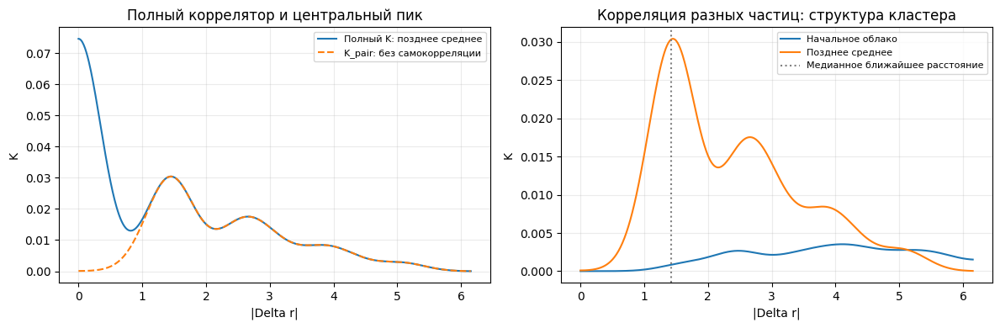

A = 273.338; sigma = 0.25; позднее окно: 240.0..300.0


In [8]:
# Один и тот же A для начального состояния и всех поздних кадров.
domain_halfwidth = np.max(np.abs(RV[0])) + 4 * sigma
A = (2 * domain_halfwidth)**2
late_frames = np.unique(np.linspace(late_index, len(t) - 1, num_corr_frames).astype(int))
R_late = RV[0][:, :, late_frames]
max_pair_distance = max(
    np.max(np.linalg.norm(R_late[:, :, None, i] - R_late[:, None, :, i], axis=0))
    for i in range(R_late.shape[2])
)
dr = np.linspace(0, max_pair_distance + 4 * sigma, 600)
K, K_pair = K_radial(R_late, dr, sigma, A)
K_initial, K_pair_initial = K_radial(RV[0, :, :, :1], dr, sigma, A)

# Плотность конечного состояния, отдельно от усреднённого коррелятора.
padding = 4 * sigma
x = np.linspace(Rfinal[0].min() - padding, Rfinal[0].max() + padding, 220)
y = np.linspace(Rfinal[1].min() - padding, Rfinal[1].max() + padding, 220)
X, Y = np.meshgrid(x, y)
density = rho(Rfinal, X, Y, sigma)

# Векторная карта: те же поздние кадры, что и для радиального графика.
delta = np.linspace(-max_pair_distance - 3 * sigma, max_pair_distance + 3 * sigma, 151)
DX, DY = np.meshgrid(delta, delta)
K2d = K_map(R_late, DX, DY, sigma, A)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
im = axes[0].pcolormesh(X, Y, density, shading='auto', cmap='magma')
axes[0].scatter(*Rfinal, s=8, c='cyan')
axes[0].set(xlabel='x', ylabel='y', aspect='equal', title='Гауссова плотность: конечный кадр')
fig.colorbar(im, ax=axes[0], label='rho')
im = axes[1].pcolormesh(DX, DY, K2d, shading='auto', cmap='viridis')
axes[1].set(xlabel='Delta x', ylabel='Delta y', aspect='equal', title='Полный K(Delta r): позднее среднее')
fig.colorbar(im, ax=axes[1], label='K')
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(dr, K, label='Полный K: позднее среднее')
axes[0].plot(dr, K_pair, '--', label='K_pair: без самокорреляции')
axes[0].set_title('Полный коррелятор и центральный пик')
axes[1].plot(dr, K_pair_initial, label='Начальное облако')
axes[1].plot(dr, K_pair, label='Позднее среднее')
axes[1].axvline(nearest_distance, color='gray', ls=':', label='Медианное ближайшее расстояние')
axes[1].set_title('Корреляция разных частиц: структура кластера')
for ax in axes:
    ax.set(xlabel='|Delta r|', ylabel='K')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print(f"A = {A:.3f}; sigma = {sigma}; позднее окно: {t[late_frames[0]]:.1f}..{t[late_frames[-1]]:.1f}")


## Как читать результат

- Анимация показывает движение от случайного облака к кластеру. К концу релаксации кинетическая энергия становится малой; конфигурация может содержать дефекты и зависит от `seed`, времени охлаждения и ловушки.
- Пики `K_pair` соответствуют характерным расстояниям между частицами. Упорядоченные структуры дают выраженные координационные оболочки; несколько пиков сами по себе не доказывают идеальный кристалл.
- Центральный пик полного K существует даже для одной частицы: это самокорреляция, а не признак кристалличности.
- Меньшая `sigma` разрешает близкие пики, большая сглаживает их. Это ширина измерения плотности, она **не меняет движение**.
- Позднее окно по умолчанию — последние 20% расчёта. Если энергия там ещё заметно меняется, это среднее по продолжающейся релаксации. Для изучения установившегося состояния увеличьте `tmax` и проверьте график энергии.
- Сравнивая разные времена или sigma в одном эксперименте, используйте одну и ту же A. Для сравнения разных N также задавайте общую A явно: автоматически выбранная область может различаться.

**Проверка численной точности:** уменьшите `max_step` вдвое и/или ужесточите `rtol`, `atol` в `gas`. Сравните конечную энергию и пики K; для динамической системы полное совпадение каждой траектории при длительном расчёте не требуется.


In [9]:
# Необязательное сохранение результатов в текущую папку:
# np.savez_compressed('gas_results.npz', t=t, RV=RV, k=k, alpha=alpha, sigma=sigma, A=A)
# np.savetxt('gas_correlator.csv', np.column_stack((dr, K, K_pair)),
#            delimiter=',', header='dr,K,K_pair', comments='')
